In [1]:
import os
from astropy.io import fits
import numpy as np
import pandas as pd
import astropy.units as u
from astropy.coordinates import SkyCoord
import seaborn as sns
import matplotlib.pyplot as plt
import os
from tqdm import tqdm
from astropy.table import Table
%matplotlib inline

In [2]:
def arcsinh_rgb(imgs, bands, scales=None,m = 0.03):
    import numpy as np
    rgbscales =dict(g=(2,6.0), r=(1,3.4), z=(0,2.2))
    if scales is not None:
        rgbscales.update(scales)

    I = 0
    for img,band in zip(imgs, bands):
        plane,scale = rgbscales[band]
        img = np.maximum(0, img * scale + m)
        I = I + img
    I /= len(bands)

    Q = 50
    fI = np.arcsinh(Q * I) / np.sqrt(Q)
    # fI = MTF(I)
    I += (I == 0.) * 1e-9
    H,W = I.shape
    rgb = np.zeros((H,W,3), np.float32)
    for img,band in zip(imgs, bands):
        plane,scale = rgbscales[band]
        rgb[:,:,plane] = (img * scale + m) * fI / I
    rgb = np.clip(rgb, 0, 1)
    return rgb

In [4]:
def plot_tar(a1, a2):
    original = fits.open("/data/public/xqf/123/DESI1/images/"+str(a1)+"_original.fits")
    generate = fits.open("/data/public/xqf/123/DESI1/images/"+str(a1)+"_generate.fits")
    labels = fits.open("/data/public/xqf/123/DESI1/images/"+str(a1)+"_label.fits")
    predict = ['Z', 'SHAPE_E1', 'SHAPE_E2']
    for i in range(generate[0].data.shape[0]):
        if i == a2:
            aaa = labels[0].data[i,:]
            # print(aaa)
            plt.subplot(121)
            plt.imshow(arcsinh_rgb(original[0].data[i,:,:,:], ["g","r","z"]))
            plt.axis('off')
            plt.subplot(122)
            g_img = generate[0].data[i,:,:,:]
            print(np.max(g_img), np.median(g_img), np.min(g_img))
            plt.imshow(arcsinh_rgb(generate[0].data[i,:,:,:], ["g","r","z"]))
            plt.axis('off')
            for j in range(len(predict)):
                plt.text(1, 1 + j * 13, f"{predict[j]}: {str(aaa[j])[:5]}",
                        color='white', ha='left', va='top', fontsize=10, alpha=0.7)
            plt.show()

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import simple_norm
from astropy.modeling.models import Sersic2D
from astropy.convolution import convolve, Gaussian2DKernel
from photutils.segmentation import detect_threshold, detect_sources
import time
import statmorph
from statmorph.utils.image_diagnostics import make_figure
%matplotlib inline

In [10]:
def ana(image):
    #   image = o_img[0,:,:]
    kernel = Gaussian2DKernel(2)
    kernel.normalize()  # make sure kernel adds up to 1
    psf = kernel.array  # we only need the numpy array
    snp = 100.0
    gain = 1e5
    sky_sigma = 1.0 / snp
    image += sky_sigma * np.random.standard_normal(size=(128, 128))
    threshold = detect_threshold(image, 1.5)
    npixels = 5  # minimum number of connected pixels
    convolved_image = convolve(image, psf)
    segmap = detect_sources(convolved_image, threshold, npixels)
    source_morphs = statmorph.source_morphology(
        image, segmap, gain=gain, psf=psf)
    morph = source_morphs[0]
    fig = make_figure(morph)

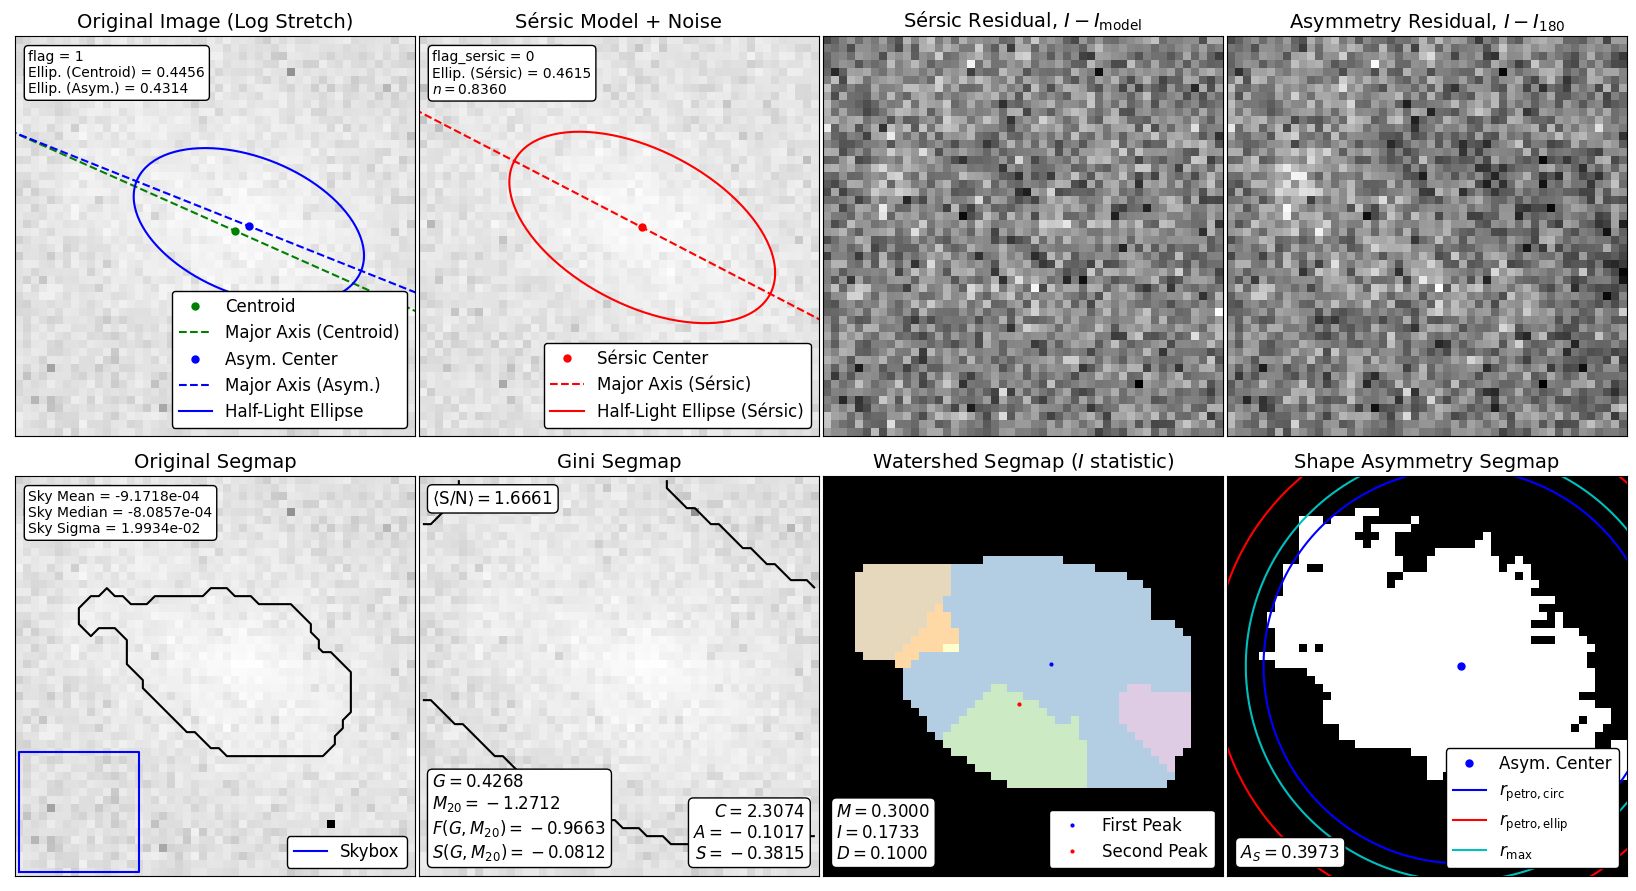

In [11]:
ana(o_img[0,:,:])

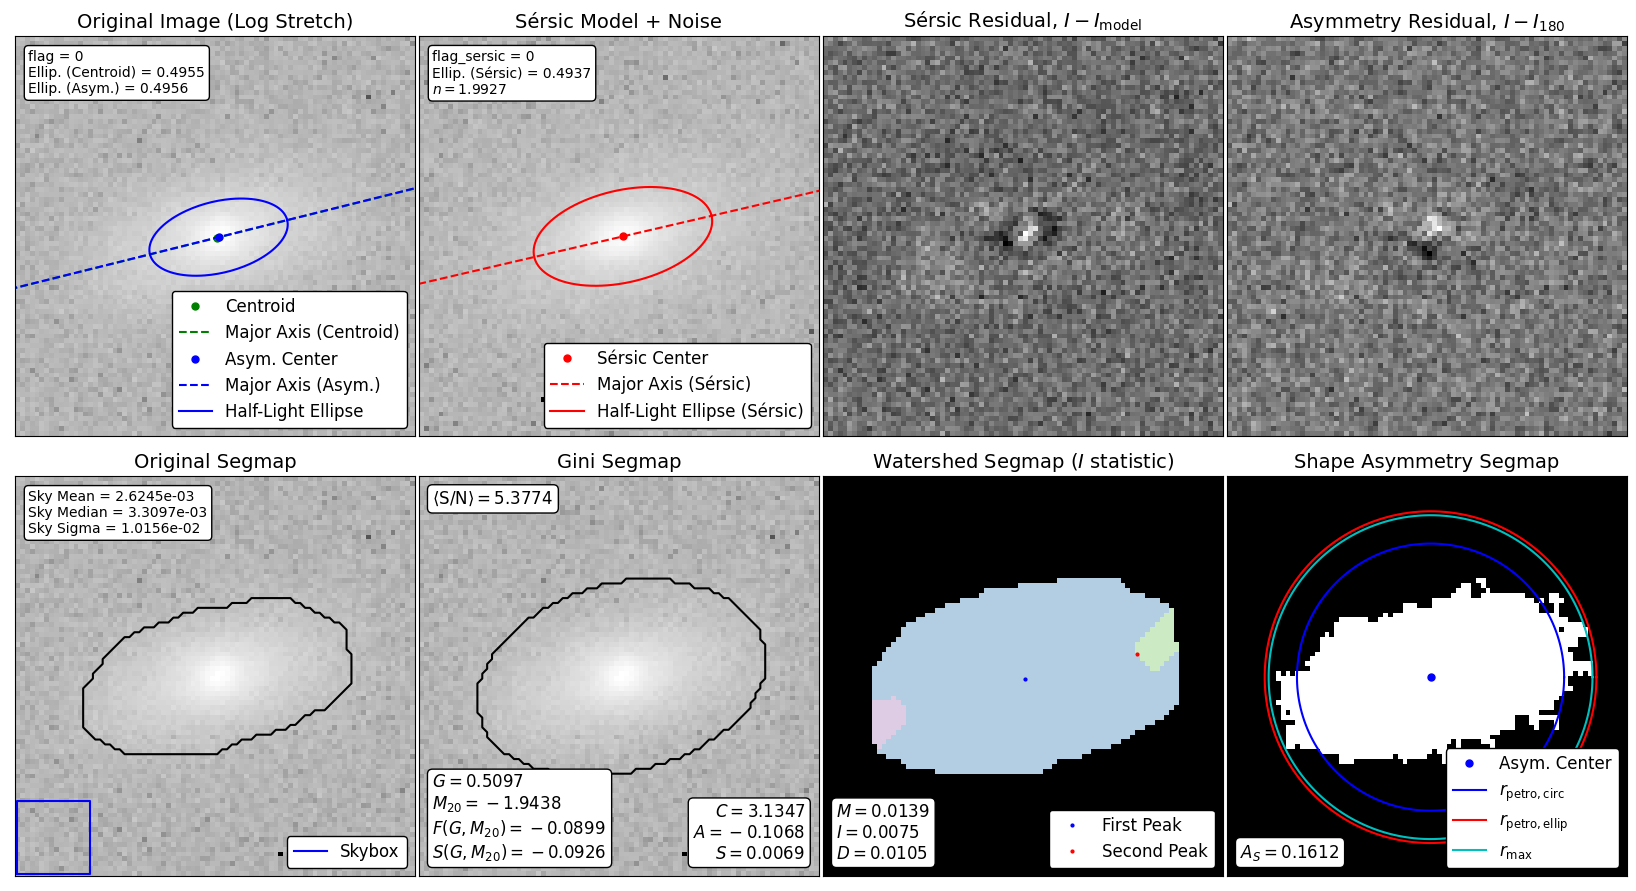

In [12]:
ana(g_img[0,:,:])

In [13]:
def plot_tar(a1, a2):
    original = fits.open("/data/public/xqf/123/DESI1/images/"+str(a1)+"_original.fits")
    generate = fits.open("/data/public/xqf/123/DESI1/images/"+str(a1)+"_generate.fits")
    labels = fits.open("/data/public/xqf/123/DESI1/images/"+str(a1)+"_label.fits")
    predict = ['Z', 'SHAPE_E1', 'SHAPE_E2']
    for i in range(generate[0].data.shape[0]):
        if i == a2:
            aaa = labels[0].data[i,:]
            # print(aaa)
            plt.subplot(121)
            o_img = original[0].data[i,:,:,:]
            plt.imshow(arcsinh_rgb(o_img, ["g","r","z"]))
            plt.axis('off')
            plt.subplot(122)
            g_img = generate[0].data[i,:,:,:]
            print(np.max(g_img), np.median(g_img), np.min(g_img))
            plt.imshow(arcsinh_rgb(g_img, ["g","r","z"]))
            plt.axis('off')
            for j in range(len(predict)):
                plt.text(1, 1 + j * 13, f"{predict[j]}: {str(aaa[j])[:5]}",
                        color='white', ha='left', va='top', fontsize=10, alpha=0.7)
            plt.show()
    ana(o_img[0,:,:])
    ana(g_img[0,:,:])

1.378464 0.0039973296 -0.010207393


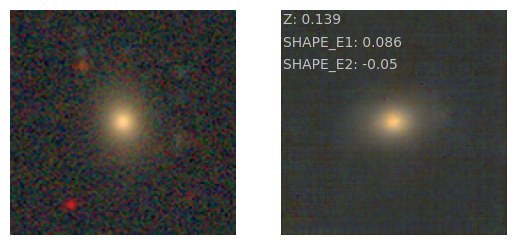

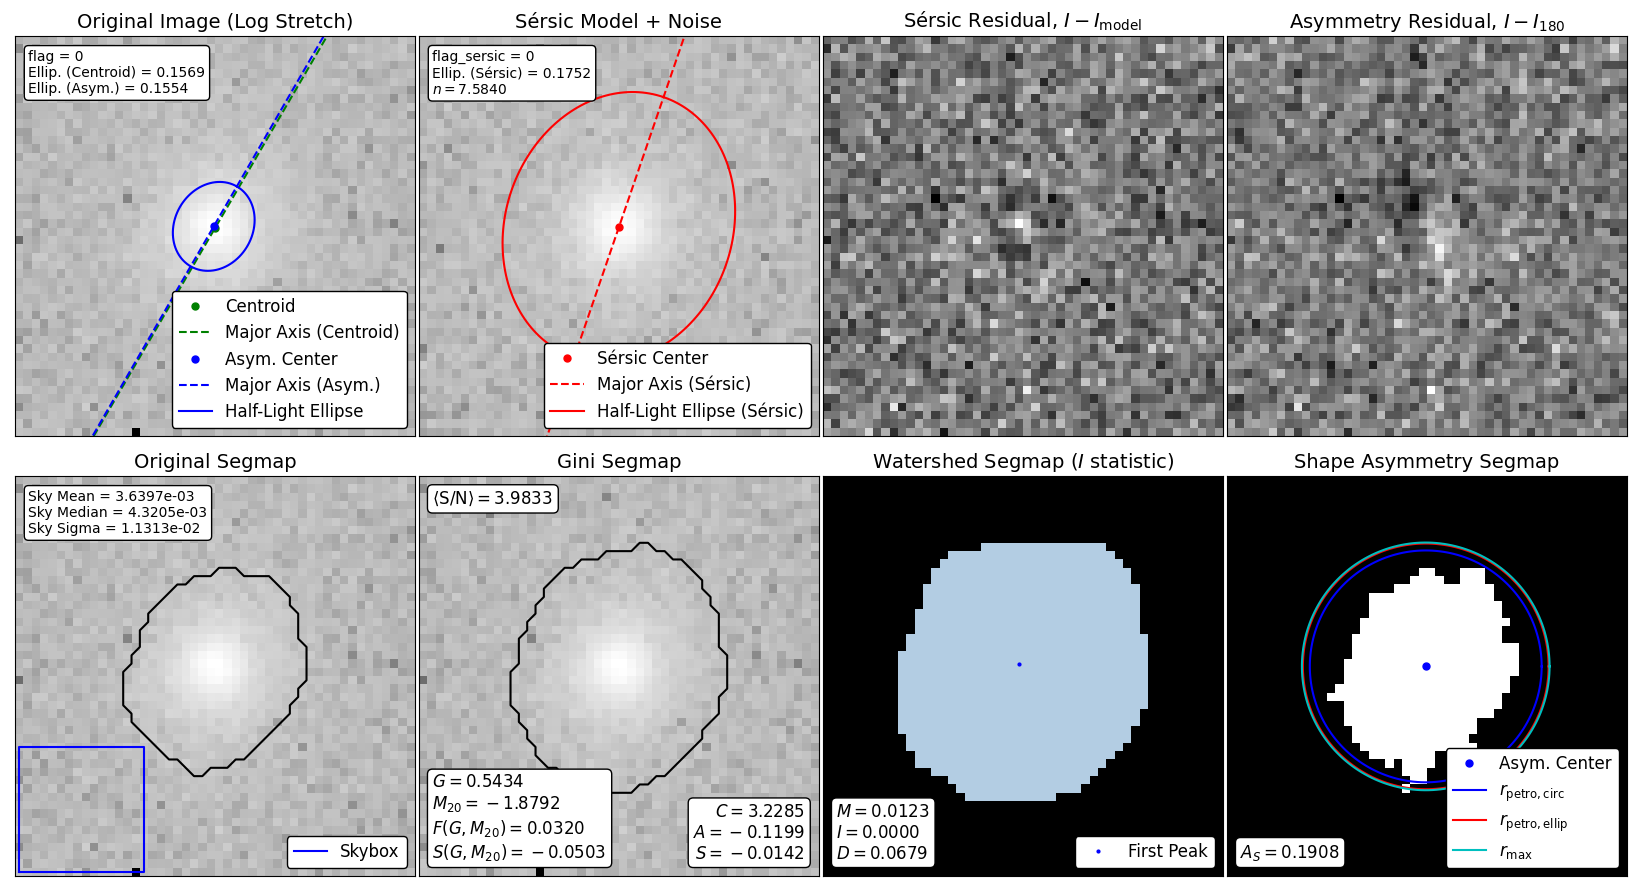

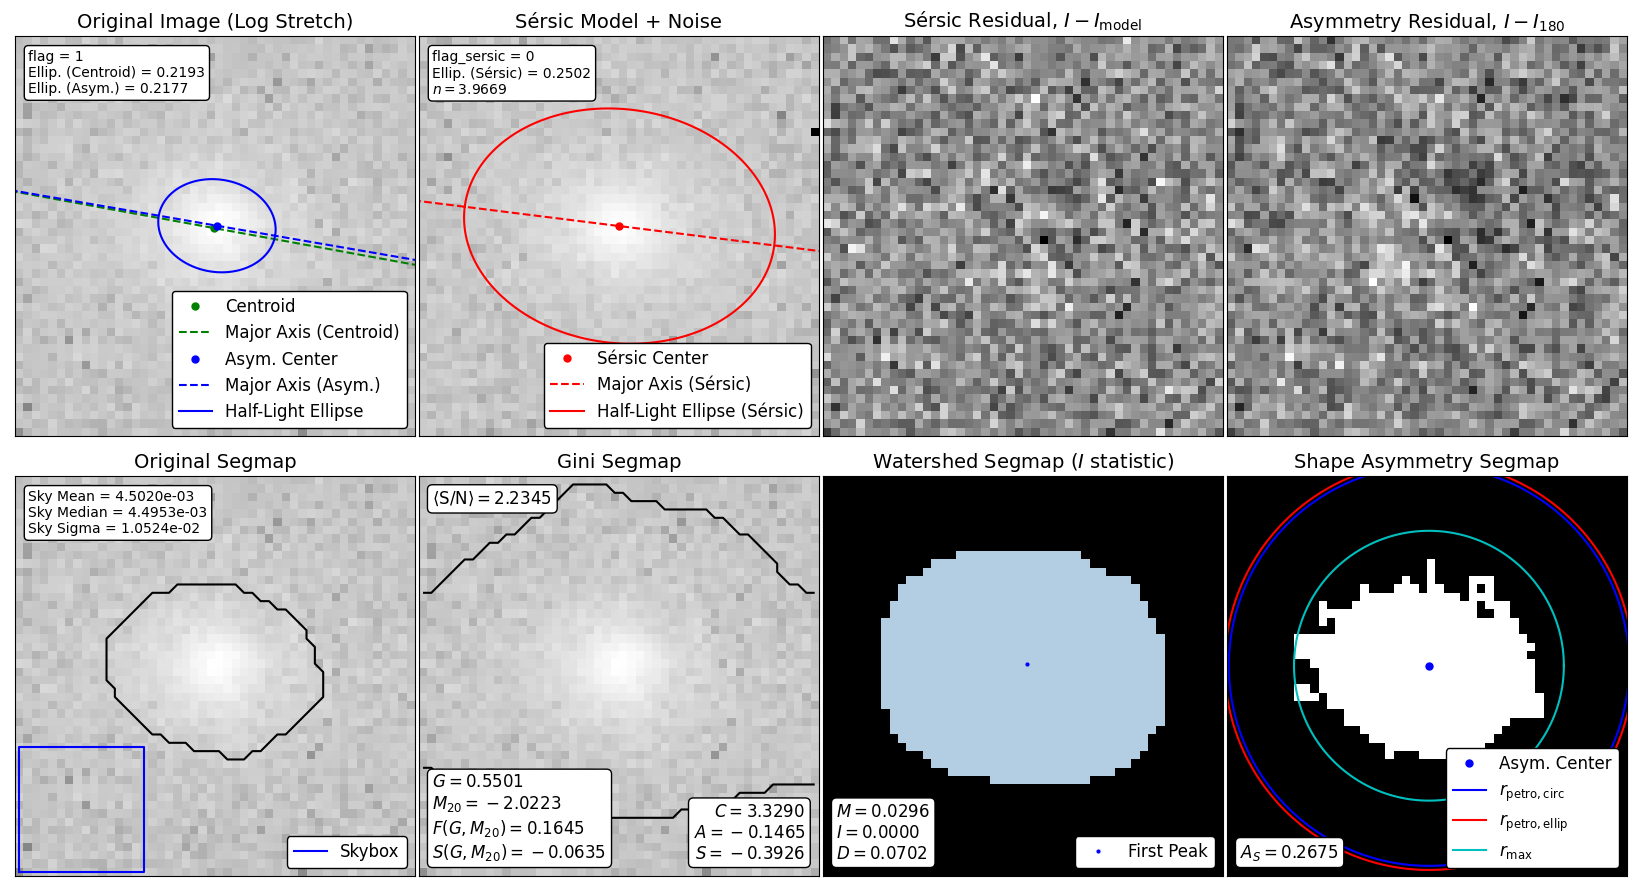

In [16]:
plot_tar(247, 3)